# P2-Lab1: Converting Raw Text into Sequence Data

We are going to load raw text, convert into tokens and indexed sequences, and perform some statistical analysis.

In [1]:
import collections
import random
import re
import torch
from d2l import torch as d2l

## The Dataset

We will work with H. G. Wells' [The Time Machine](http://www.gutenberg.org/ebooks/35), a book containing just over 30,000 words. The following `_download` method (**reads the raw text into a string**).

In [2]:
class TimeMachine(d2l.DataModule): #@save
    """The Time Machine dataset."""
    def _download(self):
        fname = d2l.download(d2l.DATA_URL + "timemachine.txt", "../data",
                             "090b5e7e70c295757f55df93cb0a180b9691891a")
        with open(fname) as f:
            return f.read()

data = TimeMachine()
raw_text = data._download()
raw_text[:60]

'The Time Machine, by H. G. Wells [1898]\n\n\n\n\nI\n\n\nThe Time Tra'

For simplicity, we ignore punctuation and capitalization when preprocessing the raw text. We show the first 60 characters preprocessed.

In [3]:
@d2l.add_to_class(TimeMachine)  #@save
def _preprocess(self, text):
    return re.sub("[^A-Za-z]+", " ", text).lower()

text = data._preprocess(raw_text)
text[:60]

'the time machine by h g wells i the time traveller for so it'

## Tokenization

*Tokens* are the atomic (indivisible) units of text. Each time step corresponds to 1 token, but what precisely constitutes a token is a **design** choice. Below, we tokenize our preprocessed text into a sequence of **characters**.

In [4]:
@d2l.add_to_class(TimeMachine)  #@save
def _tokenize(self, text):
    return list(text)

tokens = data._tokenize(text)
",".join(tokens[:30])

't,h,e, ,t,i,m,e, ,m,a,c,h,i,n,e, ,b,y, ,h, ,g, ,w,e,l,l,s, '

## Vocabulary

These tokens are still strings. However, the inputs to our models must consist of numerical inputs. First, we determine the set of unique tokens in our training *corpus*. We then assign a numerical index to each unique token. Rare vocabulary elements are often dropped for convenience. Whenever we encounter a token that had not been previously seen, we represent it by a special "&lt;unk&gt;" token, signifying that this is an *unknown* value.

In [5]:
import collections

class Vocab:  #@save
    """Vocabulary for text."""
    def __init__(self, tokens=[], min_freq=0, reserved_tokens=[]):
        # Flatten a 2D list if needed
        if tokens and isinstance(tokens[0], list):
            tokens = [token for line in tokens for token in line]
        # Count token frequencies
        counter = collections.Counter(tokens)
        self.token_freqs = sorted(counter.items(), key=lambda x: x[1],
                                  reverse=True)
        # The list of unique tokens
        self.idx_to_token = list(sorted(set(["<unk>"] + reserved_tokens + [
            token for token, freq in self.token_freqs if freq >= min_freq])))
        self.token_to_idx = {token: idx
                             for idx, token in enumerate(self.idx_to_token)}

    def __len__(self):
        return len(self.idx_to_token)

    def __getitem__(self, tokens):
        if not isinstance(tokens, (list, tuple)):
            return self.token_to_idx.get(tokens, self.unk)
        return [self.__getitem__(token) for token in tokens]

    def to_tokens(self, indices):
        if hasattr(indices, "__len__") and len(indices) > 1:
            return [self.idx_to_token[int(index)] for index in indices]
        return self.idx_to_token[indices]

    @property
    def unk(self):  # Index for the unknown token
        return self.token_to_idx["<unk>"]

We now [**construct a vocabulary**] for our dataset, converting the sequence of strings into a list of numerical indices. Note that we have not lost any information and can easily convert our dataset back to its original (string) representation.

In [6]:
vocab = Vocab(tokens)
indices = vocab[tokens[:10]]
print("indices:", indices)
print("words:", vocab.to_tokens(indices))

indices: [21, 9, 6, 0, 21, 10, 14, 6, 0, 14]
words: ['t', 'h', 'e', ' ', 't', 'i', 'm', 'e', ' ', 'm']


## Putting It All Together

Using the above classes and methods, we [**package everything into the following `build` method of the `TimeMachine` class**], which returns `corpus`, a list of token indices, and `vocab`, the vocabulary of *The Time Machine* corpus. The modifications we did here are: (i) we tokenize text into characters, not words, to simplify the training in later  ections; (ii) `corpus` is a single list, not a list of token lists, since each text line in *The Time Machine* dataset is not necessarily a sentence or paragraph.

In [7]:
@d2l.add_to_class(TimeMachine)  #@save
def build(self, raw_text, vocab=None):
    tokens = self._tokenize(self._preprocess(raw_text))
    if vocab is None: vocab = Vocab(tokens)
    corpus = [vocab[token] for token in tokens]
    return corpus, vocab

corpus, vocab = data.build(raw_text)
len(corpus), len(vocab)

(173428, 28)

## Exploratory Language Statistics

Using the real corpus and the `Vocab` class defined over words, we can inspect basic statistics concerning word use in our corpus. Below, we construct a vocabulary from words used in *The Time Machine* and print the ten most frequently occurring of them.


In [8]:
words = text.split()
vocab = Vocab(words)
vocab.token_freqs[:10]

[('the', 2261),
 ('i', 1267),
 ('and', 1245),
 ('of', 1155),
 ('a', 816),
 ('to', 695),
 ('was', 552),
 ('in', 541),
 ('that', 443),
 ('my', 440)]

Note that (**the ten most frequent words**) are not all that descriptive. Articles like "the" and "a", pronouns like "i" and "my", and prepositions like "of", "to", and "in" occur often because they serve common syntactic roles. Such words that are common but not particularly descriptive are often called (***stop words***) and, in previous generations of text classifiers based on so-called bag-of-words representations, they were most often filtered out. However, they carry meaning and it is not necessary to filter them out when working with modern RNN- and Transformer-based neural models. If you look further down the list, you will notice that word frequency decays quickly. The $10^{\textrm{th}}$ most frequent word is less than $1/5$ as common as the most popular. Word frequency tends to follow a power law distribution (Zipf Law) as we go down the ranks. To get a better idea, we [**plot the figure of the word frequency**].

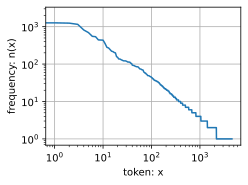

In [9]:
freqs = [freq for token, freq in vocab.token_freqs]
d2l.plot(freqs, xlabel="token: x", ylabel="frequency: n(x)",
         xscale="log", yscale="log")

After dealing with the first few words as exceptions, all the remaining words roughly follow a straight line on a log--log plot. This phenomenon is captured by *Zipf's law*, which states that the frequency $n_i$ of the $i^\textrm{th}$ most frequent word is:

$$n_i \propto \frac{1}{i^\alpha},$$

which is equivalent to

$$\log n_i = -\alpha \log i + c,$$

where $\alpha$ is the exponent that characterizes the distribution and $c$ is a constant. This should already give us pause for thought if we want to model words by counting statistics. After all, we will significantly overestimate the frequency of the tail, also known as the infrequent words. But [**what about the other word combinations, such as two consecutive words (bigrams), three consecutive words (trigrams)**], and beyond? Let's see whether the bigram frequency behaves in the same manner as the single word (unigram) frequency.

In [10]:
bigram_tokens = ["--".join(pair) for pair in zip(words[:-1], words[1:])]
bigram_vocab = Vocab(bigram_tokens)
bigram_vocab.token_freqs[:10]

[('of--the', 309),
 ('in--the', 169),
 ('i--had', 130),
 ('i--was', 112),
 ('and--the', 109),
 ('the--time', 102),
 ('it--was', 99),
 ('to--the', 85),
 ('as--i', 78),
 ('of--a', 73)]

One thing is notable here. Out of the ten most frequent word pairs, nine are composed of both stop words and only one is relevant to the actual book---"the time". Furthermore, let's see whether the trigram frequency behaves in the same manner.

In [11]:
trigram_tokens = ["--".join(triple) for triple in zip(
    words[:-2], words[1:-1], words[2:])]
trigram_vocab = Vocab(trigram_tokens)
trigram_vocab.token_freqs[:10]

[('the--time--traveller', 59),
 ('the--time--machine', 30),
 ('the--medical--man', 24),
 ('it--seemed--to', 16),
 ('it--was--a', 15),
 ('here--and--there', 15),
 ('seemed--to--me', 14),
 ('i--did--not', 14),
 ('i--saw--the', 13),
 ('i--began--to', 13)]

Now, let's [**visualize the token frequency**] among these three models: unigrams, bigrams, and trigrams.

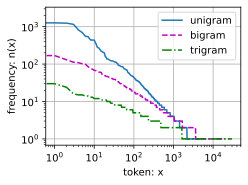

In [12]:
bigram_freqs = [freq for token, freq in bigram_vocab.token_freqs]
trigram_freqs = [freq for token, freq in trigram_vocab.token_freqs]
d2l.plot([freqs, bigram_freqs, trigram_freqs], xlabel="token: x",
         ylabel="frequency: n(x)", xscale="log", yscale="log",
         legend=["unigram", "bigram", "trigram"])

Beyond unigram words, sequences of words also appear to be following Zipf's law, albeit with a smaller exponent. The number of distinct $n$-grams is not that large. This gives us hope that there is quite a lot of structure in language. Third, many $n$-grams occur very rarely. This makes certain methods unsuitable for language modeling and motivates the use of deep learning models.

## Summary

Text is among the most common forms of sequence data encountered in deep learning. Common choices for what constitutes a token are characters, words, and word pieces. To preprocess text, we usually (i) split text into tokens; (ii) build a vocabulary to map token strings to numerical indices; and (iii) convert text data into token indices for models to manipulate. In practice, the frequency of words tends to follow Zipf's law. This is true not just for individual words (unigrams), but also for $n$-grams.

## Lab 1 Tasks

1. Execute this notebook, understanding the commands used.
2. Perform a linear fit for the exponent of Zipfian distribution for unigrams, bigrams, and trigrams to verify this law  for this corpus. Compute a metric for measuring the goodness-of-fit ($R^2$ or MSE).
3. Load the spanish text "Juvenilia" found in the virtual campus and repeat the previous analysis.
4. Compare the results obtained in both cases and extract conclusions regarding the more frequent words, characters and exponents of the Zipf Law. Compare also thes values with the general results described in the literature for larger corpus of English and Spanish.

## Resolución de los ejercicios P1

### Ejercicio 2. Ajuste lineal de la ley de Zipf (inglés)

La ley de Zipf afirma que la frecuencia del token de rango $i$ decae como $n_i \propto i^{-\alpha}$, es decir, en escala log-log se aproxima por una recta:

$$\log n_i = -\alpha \log i + c.$$

Ajustamos por mínimos cuadrados unigramas, bigramas y trigramas del corpus, y evaluamos la bondad del ajuste con $R^2$ y el MSE en escala logarítmica. La tabla muestra también el número de tokens distintos.

In [32]:
import numpy as np
import pandas as pd

def zipf_fit(token_freqs):
    freqs = np.array([freq for _, freq in token_freqs], dtype=float)
    ranks = np.arange(1, len(freqs) + 1)
    x, y = np.log(ranks), np.log(freqs)
    slope, intercept = np.polyfit(x, y, 1)
    pred = slope * x + intercept
    r2 = 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)
    mse = np.mean((y - pred) ** 2)
    return {"alpha": -slope, "c": intercept, "R2": r2, "MSE": mse, "tokens únicos": len(freqs)}

In [33]:
english_fit = {
    "unigram": zipf_fit(vocab.token_freqs),
    "bigram": zipf_fit(bigram_vocab.token_freqs),
    "trigram": zipf_fit(trigram_vocab.token_freqs),
}
english_fit_df = pd.DataFrame(english_fit).T[["alpha", "R2", "MSE", "tokens únicos"]]
english_fit_df["tokens únicos"] = english_fit_df["tokens únicos"].astype(int)
display(english_fit_df.round(4))

,alpha,R2,MSE,tokens únicos
unigram,1.0353,0.9717,0.0310,4579
bigram,0.4637,0.8101,0.0503,20234
trigram,0.1642,0.5289,0.0240,29882


In [34]:
char_vocab_en = Vocab(list(text))
top_en = pd.DataFrame({
    "palabra": [w for w, _ in vocab.token_freqs[:10]],
    "freq. palabra": [f for _, f in vocab.token_freqs[:10]],
    "carácter": ["espacio" if c == " " else c for c, _ in char_vocab_en.token_freqs[:10]],
    "freq. carácter": [f for _, f in char_vocab_en.token_freqs[:10]],
})
top_en.index = pd.RangeIndex(1, 11, name="top")
display(top_en)

,palabra,freq. palabra,carácter,freq. carácter
rango,,,,
1,the,2261,espacio,32775
2,i,1267,e,17838
3,and,1245,t,13515
4,of,1155,a,11704
5,a,816,i,10138
6,to,695,n,9917
7,was,552,o,9758
8,in,541,s,8486
9,that,443,h,8257


**Resultados (inglés).** El unigrama se ajusta muy bien ($\alpha \approx 1.035$, $R^2 \approx 0.972$): el exponente está cerca del valor teórico 1. Los bigramas y trigramas presentan exponentes menores ($\alpha \approx 0.464$ y $0.164$) y peor ajuste relativo ($R^2 \approx 0.810$ y $0.529$). Esto ocurre porque las combinaciones de varias palabras son cada vez más específicas: muchas aparecen una sola vez, la cola es más ruidosa y la recta de Zipf describe peor esos casos. En las palabras dominan artículos, pronombres y preposiciones (*the, i, and, of, a*), y en los caracteres el espacio seguido de *e, t, a, i, n*.

### Tarea 3. Repetición del análisis con *Juvenilia* (español)

Cargamos el texto en español conservando las letras acentuadas y la ñ, aplicamos el mismo tipo de preprocesado y construimos los vocabularios de palabras y de $n$-gramas. Después repetimos los ajustes de Zipf y el análisis de frecuencias.

In [42]:
def preprocess_spanish(raw):
    return re.sub(r"[^A-Za-zÁÉÍÓÚÜÑáéíóúüñ]+", " ", raw).lower()

with open("../data/Juvenilia.txt", encoding="utf-8") as f:
    raw_text_es = f.read()

text_es = preprocess_spanish(raw_text_es)
words_es = text_es.split()
vocab_es = Vocab(words_es)
bigram_vocab_es = Vocab(["--".join(pair) for pair in zip(words_es[:-1], words_es[1:])])
trigram_vocab_es = Vocab(["--".join(triple) for triple in zip(words_es[:-2], words_es[1:-1], words_es[2:])])

spanish_fit = {
    "unigram": zipf_fit(vocab_es.token_freqs),
    "bigram": zipf_fit(bigram_vocab_es.token_freqs),
    "trigram": zipf_fit(trigram_vocab_es.token_freqs),
}
spanish_fit_df = pd.DataFrame(spanish_fit).T[["alpha", "R2", "MSE", "tokens únicos"]]
spanish_fit_df["tokens únicos"] = spanish_fit_df["tokens únicos"].astype(int)
display(spanish_fit_df.round(4))

,alpha,R2,MSE,tokens únicos
unigram,0.9250,0.9618,0.0338,13547
bigram,0.4267,0.7826,0.0505,53916
trigram,0.1418,0.4825,0.0215,78165


In [36]:
char_vocab_es = Vocab(list(text_es))
top_es = pd.DataFrame({
    "palabra": [w for w, _ in vocab_es.token_freqs[:10]],
    "freq. palabra": [f for _, f in vocab_es.token_freqs[:10]],
    "carácter": ["espacio" if c == " " else c for c, _ in char_vocab_es.token_freqs[:10]],
    "freq. carácter": [f for _, f in char_vocab_es.token_freqs[:10]],
})
top_es.index = pd.RangeIndex(1, 11, name="top")
display(top_es)

,palabra,freq. palabra,carácter,freq. carácter
rango,,,,
1,de,5010,espacio,84270
2,la,3479,e,50704
3,que,2747,a,49262
4,el,2518,o,34801
5,y,2349,s,29038
6,en,2301,n,27690
7,a,1996,r,26407
8,los,1287,i,23498
9,un,1179,l,22825


**Resultados (español).** Las palabras más frecuentes vuelven a ser funcionales (*de, la, que, el, y, en*). El unigrama sigue una ley de Zipf clara ($\alpha \approx 0.925$, $R^2 \approx 0.962$); bigramas y trigramas tienen exponentes menores ($\alpha \approx 0.427$ y $0.142$) y peor ajuste ($R^2 \approx 0.783$ y $0.483$). En caracteres, tras el espacio destacan *e, a, o, s, n*, coherente con la ortografía española.

### Tarea 4. Comparación y conclusiones

La siguiente tabla resume los exponentes y la bondad del ajuste de ambos idiomas. Después se comparan las rectas de Zipf y las frecuencias relativas de los caracteres.

In [37]:
comparison = pd.concat(
    [english_fit_df[["alpha", "R2"]], spanish_fit_df[["alpha", "R2"]]],
    axis=1, keys=["Inglés", "Español"])
display(comparison.round(4))

Inglés         Español        
          alpha      R2   alpha      R2
unigram  1.0353  0.9717  0.9250  0.9618
bigram   0.4637  0.8101  0.4267  0.7826
trigram  0.1642  0.5289  0.1418  0.4825

Curvas empíricas (trazo claro) y rectas de Zipf ajustadas (trazo discontinuo) para unigramas, bigramas y trigramas en cada idioma:

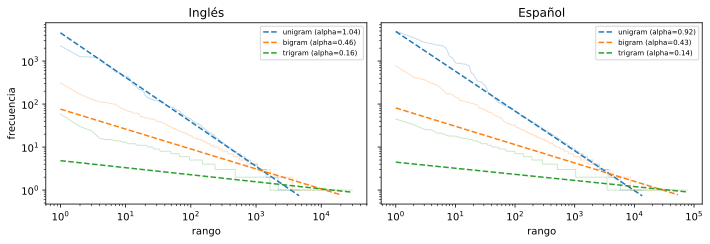

In [39]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
english_vocabs = {"unigram": vocab, "bigram": bigram_vocab, "trigram": trigram_vocab}
spanish_vocabs = {"unigram": vocab_es, "bigram": bigram_vocab_es, "trigram": trigram_vocab_es}
for ax, title, fits, vocabs in [(axes[0], "Inglés", english_fit, english_vocabs),
                                (axes[1], "Español", spanish_fit, spanish_vocabs)]:
    for name, color in [("unigram", "C0"), ("bigram", "C1"), ("trigram", "C2")]:
        r = fits[name]
        ranks = np.arange(1, r["tokens únicos"] + 1)
        freqs = [f for _, f in vocabs[name].token_freqs]
        ax.plot(ranks, freqs, color=color, alpha=0.25, linewidth=1)
        ax.plot(ranks, np.exp(r["c"]) * ranks ** (-r["alpha"]), linestyle="--",
                color=color, label=f"{name} (alpha={r['alpha']:.2f})")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("top")
    ax.set_title(title)
    ax.legend(fontsize=7)
axes[0].set_ylabel("frecuencia")
plt.tight_layout()
plt.show()

Frecuencia relativa de los diez caracteres más comunes (el espacio se etiqueta como «espacio»):

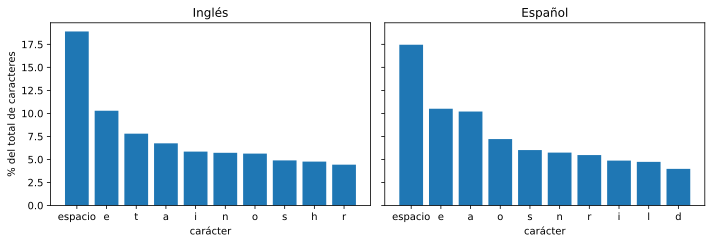

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, title, cv in [(axes[0], "Inglés", char_vocab_en), (axes[1], "Español", char_vocab_es)]:
    tokens = [t for t, _ in cv.token_freqs[:10]]
    labels = ["espacio" if t == " " else t for t in tokens]
    freqs = np.array([f for _, f in cv.token_freqs[:10]], dtype=float)
    pct = 100 * freqs / sum(f for _, f in cv.token_freqs)
    ax.bar(labels, pct)
    ax.set_title(title)
    ax.set_xlabel("carácter")
axes[0].set_ylabel("% del total de caracteres")
plt.tight_layout()
plt.show()

**Conclusiones.**
- **Palabras más frecuentes:** en inglés dominan *the, i, and, of, a*; en español, *de, la, que, el, y*. En ambos casos son palabras funcionales, que aparecen continuamente para dar estructura gramatical y por eso encabezan el ranking.
- **Caracteres:** el espacio es el más frecuente en los dos textos. Después aparecen *e, t, a* en inglés y *e, a, o* en español, en línea con las frecuencias típicas de cada idioma.
- **Exponentes de Zipf:** los unigramas se acercan a $\alpha \approx 1$ (1.035 en inglés y 0.925 en español). Bigramas y trigramas tienen exponentes mucho menores (0.46/0.16 y 0.43/0.14), porque las secuencias largas son más específicas y muchas solo aparecen una vez.
- **Bondad del ajuste:** $R^2$ es alto para unigramas (0.972 y 0.962) y desciende para bigramas y trigramas (0.810/0.529 y 0.783/0.483). El MSE logarítmico es pequeño, pero el ajuste relativo empeora al aumentar $n$ por la dispersión de la cola.
- **Comparación con la literatura:** los corpus grandes de inglés suelen dar $\alpha \approx 1.0$--$1.1$ y los de español valores cercanos a $0.9$--$1.0$, coherentes con lo obtenido. Las diferencias se explican por el tamaño limitado de estos corpus y por el preprocesado, pero en ambos idiomas se confirma el comportamiento de la ley de Zipf.